In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ACIT4030/Assignment2"
ZIP_PATH = os.path.join(PROJECT_DIR, "acit4030-data.zip")
DATA_DIR = "/content/acit4030_data"
DATA_ROOT = os.path.join(DATA_DIR, "data")
PYTORCH3D_WHEEL = "/content/drive/MyDrive/3Dvison/pytorch3d_wheel/pytorch3d-0.7.9-cp312-cp312-linux_x86_64.whl"

IMAGE_SIZE = (128, 128)
N_ITER = 15000
LR = 1e-3
LR_DROP_ITER = round(N_ITER * 2250 / 3500)
BATCH_SIZE = 6
N_RAYS_PER_IMAGE = 750
N_PTS_PER_RAY = 128
LEGO_DEPTH = (2.0, 6.0)
POSTER_DEPTH = (1.0, 6.0)
POSTER_TEST_EVERY = 8
SEED = 1

BASELINE_DIR = os.path.join(PROJECT_DIR, f"baseline_{N_ITER // 1000}k")

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!pip install -q fvcore iopath {PYTORCH3D_WHEEL}

import glob
import ctypes
import torch

for lib in glob.glob("/usr/local/lib/python3*/dist-packages/nvidia/cuda_runtime/lib/libcudart.so.12*")[:1]:
    ctypes.CDLL(lib, mode=ctypes.RTLD_GLOBAL)
torch_lib = os.path.join(os.path.dirname(torch.__file__), "lib")
for name in ["libc10.so", "libtorch_cpu.so", "libtorch.so", "libc10_cuda.so", "libtorch_python.so"]:
    if os.path.exists(os.path.join(torch_lib, name)):
        ctypes.CDLL(os.path.join(torch_lib, name), mode=ctypes.RTLD_GLOBAL)

device = torch.device("cuda")
print(torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
NVIDIA L4


In [ ]:
import sys
import shutil

REPO_DIR = os.path.join(PROJECT_DIR, "3D-Deep-Learning-with-Python")
WORK_DIR = os.path.join(PROJECT_DIR, "nerf_assignment")

if not os.path.exists(REPO_DIR):
    !git clone --depth 1 https://github.com/PacktPublishing/3D-Deep-Learning-with-Python.git {REPO_DIR}
if not os.path.exists(WORK_DIR):
    shutil.copytree(os.path.join(REPO_DIR, "chap6"), WORK_DIR)

os.chdir(WORK_DIR)
sys.path.append(WORK_DIR)

from nerf_model import NeuralRadianceField, HarmonicEmbedding
from utils.helper_functions import huber, sample_images_at_mc_locs

In [ ]:
import zipfile
import importlib.util

loader_path = os.path.join(DATA_ROOT, "load_nerf_data.py")
if not os.path.exists(loader_path):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

spec = importlib.util.spec_from_file_location("load_nerf_data", loader_path)
loader = importlib.util.module_from_spec(spec)
spec.loader.exec_module(loader)
load_nerf_data = loader.load_nerf_data

LEGO_DIR = os.path.join(DATA_ROOT, "lego")
POSTER_DIR = os.path.join(DATA_ROOT, "poster")

lego_images, lego_silhouettes, lego_cameras = load_nerf_data(LEGO_DIR, split="train", device=device, resize_to=IMAGE_SIZE)
lego_test_images, lego_test_silhouettes, lego_test_cameras = load_nerf_data(LEGO_DIR, split="test", device=device, resize_to=IMAGE_SIZE)
poster_images, poster_silhouettes, poster_cameras = load_nerf_data(POSTER_DIR, split="train", device=device, resize_to=IMAGE_SIZE)

lego_train_idx = torch.arange(len(lego_cameras), device=device)
poster_test_idx = torch.arange(0, len(poster_cameras), POSTER_TEST_EVERY, device=device)
poster_train_idx = torch.tensor([i for i in range(len(poster_cameras)) if i % POSTER_TEST_EVERY != 0], device=device)

Loading transforms_train.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading train split with 50 frames.
Loaded image dimensions: 800x800
Resizing images to: 128x128
Calculated Vertical FOV for camera: 39.598 degrees
Loading transforms_test.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading test split with 20 frames.
Loaded image dimensions: 800x800
Resizing images to: 128x128
Calculated Vertical FOV for camera: 39.598 degrees
Using explicit intrinsics from transforms.json (scaled for 128x128):
  fl_x=135.96, fl_y=77.26, cx=64.00, cy=64.00
Loading train split with 226 frames.
Loaded image dimensions: 1080x1920
Resizing images to: 128x128
Calculated Vertical FOV for camera: 79.278 degrees
Found 'applied_transform' in transforms.json. Applying it to camera poses.


In [ ]:
import json
from pytorch3d.renderer import FoVPerspectiveCameras


def fix_camera_convention(cameras, aspect_ratio=1.0):
    flip = torch.tensor([-1.0, 1.0, -1.0], device=device)
    return FoVPerspectiveCameras(
        R=cameras.R.transpose(1, 2) * flip,
        T=cameras.T * flip,
        znear=cameras.znear,
        zfar=cameras.zfar,
        aspect_ratio=torch.full((len(cameras),), float(aspect_ratio), device=device),
        fov=cameras.fov,
        device=device,
    )


with open(os.path.join(POSTER_DIR, "transforms.json")) as f:
    m = json.load(f)
poster_aspect = (m["w"] / m["fl_x"]) / (m["h"] / m["fl_y"])

lego_cameras = fix_camera_convention(lego_cameras)
lego_test_cameras = fix_camera_convention(lego_test_cameras)
poster_cameras = fix_camera_convention(poster_cameras, poster_aspect)

for t in [lego_images, lego_silhouettes, lego_test_images, lego_test_silhouettes, poster_images, poster_silhouettes]:
    t.clamp_(0.0, 1.0)

In [ ]:
from pytorch3d.renderer import MonteCarloRaysampler, NDCMultinomialRaysampler, EmissionAbsorptionRaymarcher, ImplicitRenderer


def make_renderers(min_depth, max_depth):
    renderer_mc = ImplicitRenderer(
        raysampler=MonteCarloRaysampler(
            min_x=-1.0, max_x=1.0, min_y=-1.0, max_y=1.0, n_rays_per_image=N_RAYS_PER_IMAGE,
            n_pts_per_ray=N_PTS_PER_RAY, min_depth=min_depth, max_depth=max_depth,
        ),
        raymarcher=EmissionAbsorptionRaymarcher(),
    ).to(device)
    renderer_grid = ImplicitRenderer(
        raysampler=NDCMultinomialRaysampler(
            image_height=IMAGE_SIZE[0], image_width=IMAGE_SIZE[1],
            n_pts_per_ray=N_PTS_PER_RAY, min_depth=min_depth, max_depth=max_depth,
        ),
        raymarcher=EmissionAbsorptionRaymarcher(),
    ).to(device)
    return renderer_mc, renderer_grid


lego_renderer_mc, lego_renderer_grid = make_renderers(*LEGO_DEPTH)
poster_renderer_mc, poster_renderer_grid = make_renderers(*POSTER_DEPTH)


def select_cameras(cameras, idx):
    return FoVPerspectiveCameras(
        R=cameras.R[idx], T=cameras.T[idx], znear=cameras.znear[idx], zfar=cameras.zfar[idx],
        aspect_ratio=cameras.aspect_ratio[idx], fov=cameras.fov[idx], device=device,
    )


DATA = {
    "lego": dict(images=lego_images, silhouettes=lego_silhouettes, cameras=lego_cameras, train_idx=lego_train_idx,
                 renderer_mc=lego_renderer_mc, use_silhouette=True),
    "poster": dict(images=poster_images, silhouettes=poster_silhouettes, cameras=poster_cameras, train_idx=poster_train_idx,
                   renderer_mc=poster_renderer_mc, use_silhouette=False),
}
TEST = {
    "lego": (lego_test_images, lego_test_cameras, list(range(len(lego_test_images))), lego_renderer_grid),
    "poster": (poster_images, poster_cameras, poster_test_idx.tolist(), poster_renderer_grid),
}

In [ ]:
import time

BUILDERS = {"baseline": lambda name: NeuralRadianceField().to(device)}
OPTIMIZERS = {"baseline": lambda model, scale: torch.optim.Adam(model.parameters(), lr=LR * scale)}
FOLDERS = {"baseline": (BASELINE_DIR, 500)}


def train_step(model, optimizer, images, silhouettes, cameras, train_idx, renderer_mc, use_silhouette):
    optimizer.zero_grad()
    b = train_idx[torch.randperm(len(train_idx), device=device)[:BATCH_SIZE]]
    rendered, rays = renderer_mc(cameras=select_cameras(cameras, b), volumetric_function=model)
    rgb, sil = rendered.split([3, 1], dim=-1)
    loss = huber(rgb, sample_images_at_mc_locs(images[b], rays.xys)).abs().mean()
    if use_silhouette:
        loss = loss + huber(sil, sample_images_at_mc_locs(silhouettes[b, ..., None], rays.xys)).abs().mean()
    if hasattr(model, "tv_loss"):
        loss = loss + TV_WEIGHT * model.tv_loss()
    loss.backward()
    optimizer.step()
    return loss


def train(kind, name):
    save_dir, save_every = FOLDERS[kind]
    os.makedirs(save_dir, exist_ok=True)
    torch.manual_seed(SEED)
    model = BUILDERS[kind](name)
    optimizer = OPTIMIZERS[kind](model, 1.0)
    save_time = 0.0
    torch.cuda.synchronize()
    t0 = time.time()
    for it in range(N_ITER):
        if it == LR_DROP_ITER:
            optimizer = OPTIMIZERS[kind](model, 0.1)
        loss = train_step(model, optimizer, **DATA[name])
        if (it + 1) % save_every == 0 or it + 1 == N_ITER:
            torch.cuda.synchronize()
            s0 = time.time()
            torch.save({"model_state_dict": model.state_dict(), "train_time_s": s0 - t0 - save_time},
                       os.path.join(save_dir, f"{name}_{kind}_{it + 1}.pth"))
            save_time += time.time() - s0
            print(f"[{name}/{kind}] {it + 1}/{N_ITER} | loss {loss.item():.5f}")


def checkpoint(kind, name, it):
    return os.path.join(FOLDERS[kind][0], f"{name}_{kind}_{it}.pth")


def load(kind, name, it=N_ITER):
    model = BUILDERS[kind](name)
    model.load_state_dict(torch.load(checkpoint(kind, name, it), map_location=device)["model_state_dict"])
    model.eval()
    return model


def train_or_load(kind, name):
    if not os.path.exists(checkpoint(kind, name, N_ITER)):
        train(kind, name)
    return load(kind, name)

In [ ]:
lego_nerf = train_or_load("baseline", "lego")
poster_nerf = train_or_load("baseline", "poster")

Dataset          Model  Iterations  Params_M   PSNR_dB  PSNR_std     SSIM  SSIM_std      MSE
   lego Baseline (MLP)       15000  0.317188 21.221960  1.179621 0.857254  0.009906 0.007849
 poster Baseline (MLP)       15000  0.317188 20.572604  1.419382 0.525261  0.056235 0.009176


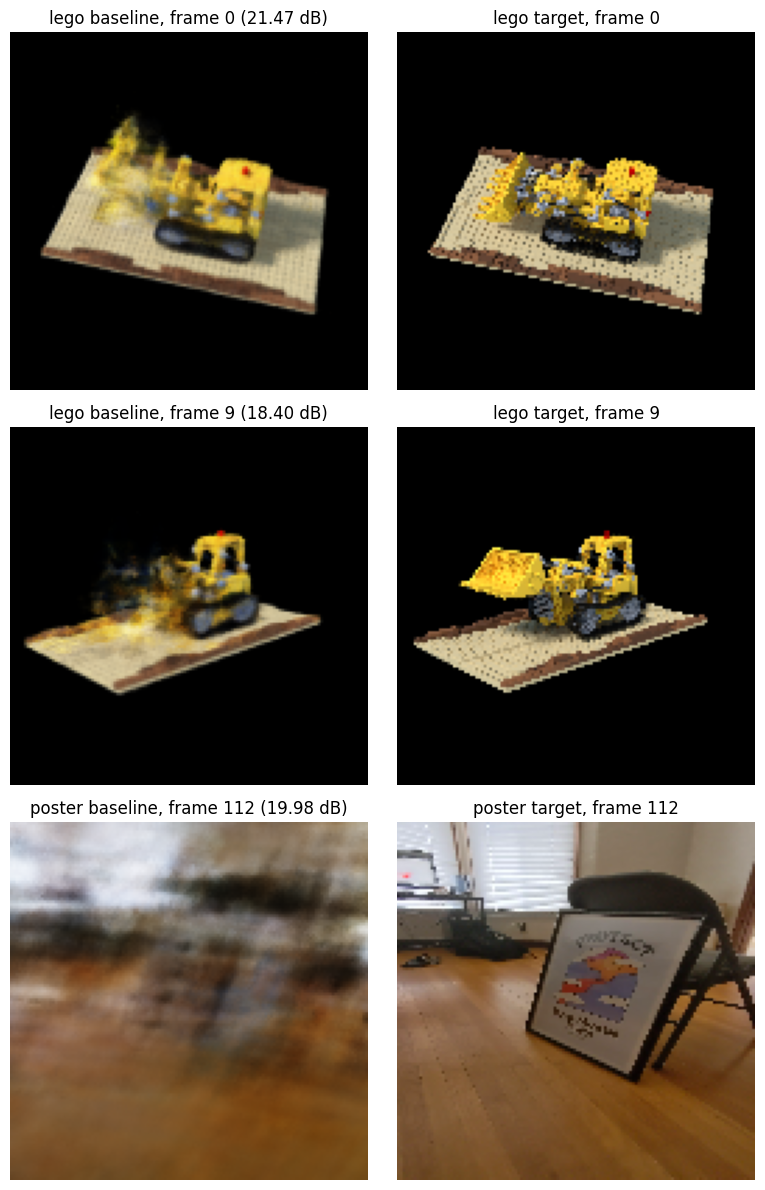

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim


def calculate_metrics(pred, target):
    pred, target = pred.cpu().clamp(0, 1), target.cpu().clamp(0, 1)
    mse = torch.mean((pred - target) ** 2).item()
    return mse, 10 * np.log10(1.0 / mse), ssim(target.numpy(), pred.numpy(), channel_axis=-1, data_range=1.0)


@torch.no_grad()
def render_view(model, cameras, frame_idx, renderer_grid):
    camera = select_cameras(cameras, torch.tensor([frame_idx], device=device))
    return renderer_grid(cameras=camera, volumetric_function=model.batched_forward)[0][0, ..., :3].clamp(0, 1)


def evaluate(model, images, cameras, frame_indices, renderer_grid):
    rows = [calculate_metrics(render_view(model, cameras, i, renderer_grid), images[i]) for i in frame_indices]
    return pd.DataFrame(rows, columns=["mse", "psnr", "ssim"])


def summary_row(name, model_name, model, res):
    return {"Dataset": name, "Model": model_name, "Iterations": N_ITER,
            "Params_M": sum(p.numel() for p in model.parameters()) / 1e6,
            "PSNR_dB": res.psnr.mean(), "PSNR_std": res.psnr.std(),
            "SSIM": res.ssim.mean(), "SSIM_std": res.ssim.std(), "MSE": res.mse.mean()}


baseline_models = {"lego": lego_nerf, "poster": poster_nerf}
baseline_rows = [summary_row(name, "Baseline (MLP)", model, evaluate(model, *TEST[name]))
                 for name, model in baseline_models.items()]
baseline_summary = pd.DataFrame(baseline_rows)
baseline_summary.to_csv(os.path.join(BASELINE_DIR, f"baseline_summary_{N_ITER}.csv"), index=False)
print(baseline_summary.to_string(index=False))

views = [("lego", 0), ("lego", 9), ("poster", 112)]
fig, axes = plt.subplots(len(views), 2, figsize=(8, 4 * len(views)))
for row, (name, fidx) in enumerate(views):
    imgs, cams, _, rgrid = TEST[name]
    pred = render_view(baseline_models[name], cams, fidx, rgrid)
    axes[row, 0].imshow(pred.cpu())
    axes[row, 0].set_title(f"{name} baseline, frame {fidx} ({calculate_metrics(pred, imgs[fidx])[1]:.2f} dB)")
    axes[row, 1].imshow(imgs[fidx].cpu())
    axes[row, 1].set_title(f"{name} target, frame {fidx}")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(BASELINE_DIR, f"baseline_qualitative_{N_ITER}.png"), dpi=200, bbox_inches="tight")
plt.show()

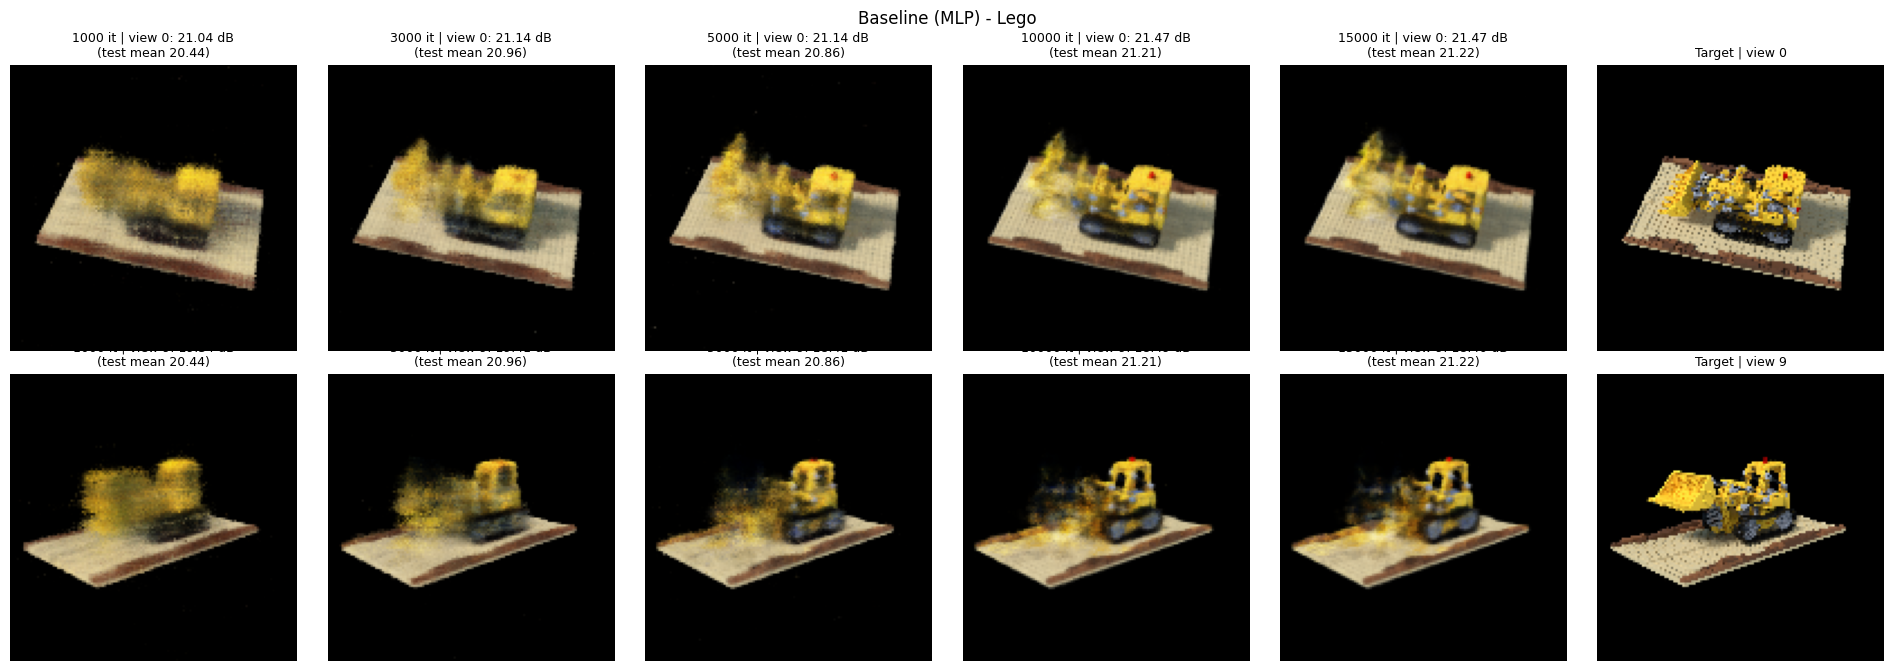

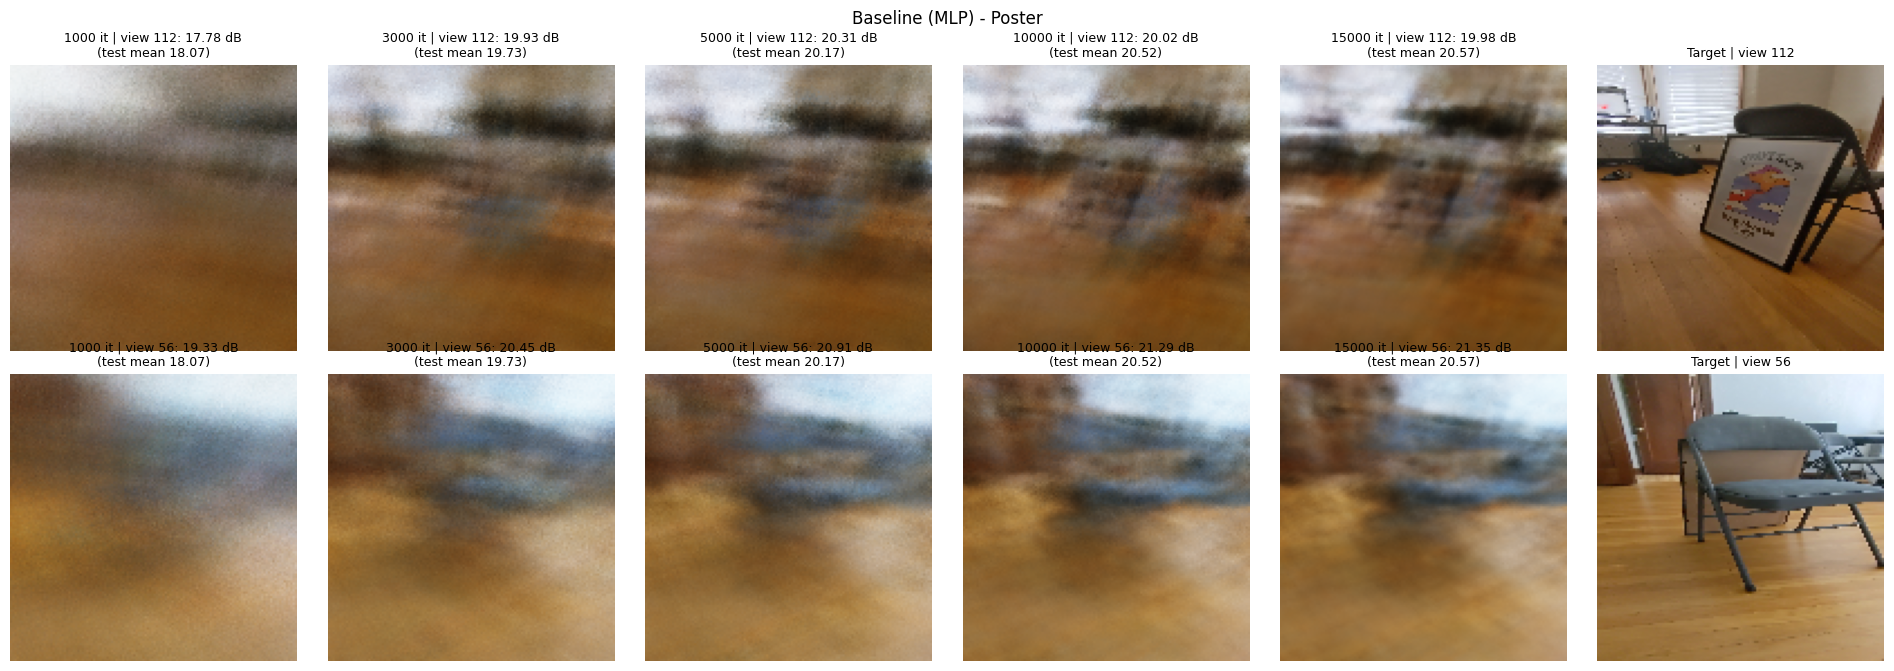

In [ ]:
SNAPSHOTS = [1000, 3000, 5000, 10000, 15000]
SNAPSHOT_VIEWS = {"lego": [0, 9], "poster": [112, 56]}


def progress(kind, title, name):
    imgs, cams, test_frames, rgrid = TEST[name]
    views = SNAPSHOT_VIEWS[name]
    fig, axes = plt.subplots(len(views), len(SNAPSHOTS) + 1, figsize=(3.2 * (len(SNAPSHOTS) + 1), 3.4 * len(views)))
    for col, it in enumerate(SNAPSHOTS):
        model = load(kind, name, it)
        test_psnr = evaluate(model, imgs, cams, test_frames, rgrid).psnr.mean()
        for row, v in enumerate(views):
            img = render_view(model, cams, v, rgrid)
            axes[row, col].imshow(img.cpu())
            axes[row, col].set_title(f"{it} it | view {v}: {calculate_metrics(img, imgs[v])[1]:.2f} dB\n(test mean {test_psnr:.2f})",
                                     fontsize=9)
            axes[row, col].axis("off")
        del model
        torch.cuda.empty_cache()
    for row, v in enumerate(views):
        axes[row, -1].imshow(imgs[v].cpu())
        axes[row, -1].set_title(f"Target | view {v}", fontsize=9)
        axes[row, -1].axis("off")
    fig.suptitle(f"{title} - {name.capitalize()}", fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(FOLDERS[kind][0], f"{name}_{kind}_progress.png"), dpi=200, bbox_inches="tight")
    plt.show()


for name in ["lego", "poster"]:
    progress("baseline", "Baseline (MLP)", name)

In [ ]:
import torch.nn.functional as F
from pytorch3d.renderer import ray_bundle_to_ray_points

GRID_RES = 128
GRID_FEATURES = 12
GRID_LR = 0.1
DENSITY_INIT = -8.0
TV_WEIGHT = 1e-4
COLOR_HIDDEN = 128
VOXEL_DIR = os.path.join(PROJECT_DIR, f"voxel_r{GRID_RES}_tv{TV_WEIGHT:g}_camsv2")


def scene_box(cameras):
    C = cameras.get_camera_center()
    f = F.normalize(cameras.R[:, :, 2], dim=-1)
    A = torch.eye(3, device=device) - f[:, :, None] * f[:, None, :]
    p = torch.linalg.solve(A.sum(0), (A @ C[:, :, None]).sum(0))[:, 0]
    half = 0.95 * (C - p).norm(dim=-1).min().item() / 3 ** 0.5
    return tuple((p - half).tolist()), tuple((p + half).tolist())


BBOX = {"lego": ((-1.5, -1.5, -1.5), (1.5, 1.5, 1.5)), "poster": scene_box(poster_cameras)}


class VoxelGridField(torch.nn.Module):
    def __init__(self, bbox, resolution, n_features, density_init, color_hidden, use_background, n_dir_harmonics=4):
        super().__init__()
        self.register_buffer("bbox_min", torch.tensor(bbox[0]))
        self.register_buffer("bbox_max", torch.tensor(bbox[1]))
        R = resolution
        self.density_grid = torch.nn.Parameter(torch.full((1, 1, R, R, R), density_init))
        self.feature_grid = torch.nn.Parameter(torch.zeros(1, n_features, R, R, R))
        self.dir_embedding = HarmonicEmbedding(n_harmonic_functions=n_dir_harmonics, omega0=1.0)
        dir_dim = n_dir_harmonics * 6
        self.color_net = torch.nn.Sequential(
            torch.nn.Linear(n_features + dir_dim, color_hidden), torch.nn.Softplus(beta=10.0),
            torch.nn.Linear(color_hidden, 3), torch.nn.Sigmoid())
        self.use_background = use_background
        if use_background:
            self.bg_net = torch.nn.Sequential(
                torch.nn.Linear(dir_dim, 64), torch.nn.Softplus(beta=10.0),
                torch.nn.Linear(64, 3), torch.nn.Sigmoid())

    def _sample(self, grid, coords):
        out = F.grid_sample(grid, coords.view(1, -1, 1, 1, 3), mode="bilinear", align_corners=True)
        return out.view(grid.shape[1], -1).t()

    def forward(self, ray_bundle, **kwargs):
        points = ray_bundle_to_ray_points(ray_bundle)
        shape = points.shape[:-1]
        coords = (points.reshape(-1, 3) - self.bbox_min) / (self.bbox_max - self.bbox_min) * 2.0 - 1.0
        inside = (coords.abs() <= 1.0).all(dim=-1, keepdim=True).float()

        sigma = F.softplus(self._sample(self.density_grid, coords)) * inside
        opacity = (1.0 - torch.exp(-sigma)).view(*shape, 1)

        dir_emb = self.dir_embedding(F.normalize(ray_bundle.directions, dim=-1))
        dir_emb_pts = dir_emb[..., None, :].expand(*shape, dir_emb.shape[-1]).reshape(-1, dir_emb.shape[-1])
        colors = self.color_net(torch.cat([self._sample(self.feature_grid, coords), dir_emb_pts], -1)).view(*shape, 3)

        if self.use_background:
            opacity = torch.cat([opacity[..., :-1, :], torch.ones_like(opacity[..., -1:, :])], dim=-2)
            colors = torch.cat([colors[..., :-1, :], self.bg_net(dir_emb)[..., None, :]], dim=-2)
        return opacity, colors

    batched_forward = NeuralRadianceField.batched_forward

    def tv_loss(self):
        def tv(g):
            return ((g[:, :, 1:] - g[:, :, :-1]).pow(2).mean()
                    + (g[:, :, :, 1:] - g[:, :, :, :-1]).pow(2).mean()
                    + (g[:, :, :, :, 1:] - g[:, :, :, :, :-1]).pow(2).mean())
        return tv(self.density_grid) + tv(self.feature_grid)


def build_voxel(name):
    return VoxelGridField(BBOX[name], GRID_RES, GRID_FEATURES, DENSITY_INIT, COLOR_HIDDEN,
                          use_background=(name == "poster")).to(device)


def voxel_optimizer(model, scale):
    nets = list(model.color_net.parameters()) + (list(model.bg_net.parameters()) if model.use_background else [])
    return torch.optim.Adam([
        {"params": [model.density_grid, model.feature_grid], "lr": GRID_LR * scale},
        {"params": nets, "lr": LR * scale},
    ])


BUILDERS["voxel"] = build_voxel
OPTIMIZERS["voxel"] = voxel_optimizer
FOLDERS["voxel"] = (VOXEL_DIR, 1000)

In [ ]:
lego_voxel = train_or_load("voxel", "lego")
poster_voxel = train_or_load("voxel", "poster")

In [ ]:
def ms_per_iteration(kind, n=50):
    model = BUILDERS[kind]("lego")
    optimizer = OPTIMIZERS[kind](model, 1.0)
    for _ in range(5):
        train_step(model, optimizer, **DATA["lego"])
    torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n):
        train_step(model, optimizer, **DATA["lego"])
    torch.cuda.synchronize()
    del model, optimizer
    torch.cuda.empty_cache()
    return (time.time() - t0) / n * 1000


ms_mlp = ms_per_iteration("baseline")
ms_vox = ms_per_iteration("voxel")
print(f"Baseline MLP: {ms_mlp:.1f} ms/it | Voxel grid: {ms_vox:.1f} ms/it | speed-up x{ms_mlp / ms_vox:.2f}")

Baseline MLP: 210.7 ms/it | Voxel grid: 80.9 ms/it | speed-up x2.60


Dataset          Model  Iterations  Params_M   PSNR_dB  PSNR_std     SSIM  SSIM_std      MSE
   lego Baseline (MLP)       15000  0.317188 21.221960  1.179621 0.857254  0.009906 0.007849
   lego     Voxel grid       15000 27.268099 20.820567  1.000712 0.822343  0.019589 0.008520
 poster Baseline (MLP)       15000  0.317188 20.572604  1.419382 0.525261  0.056235 0.009176
 poster     Voxel grid       15000 27.269894 19.786372  1.640746 0.622794  0.060850 0.011195


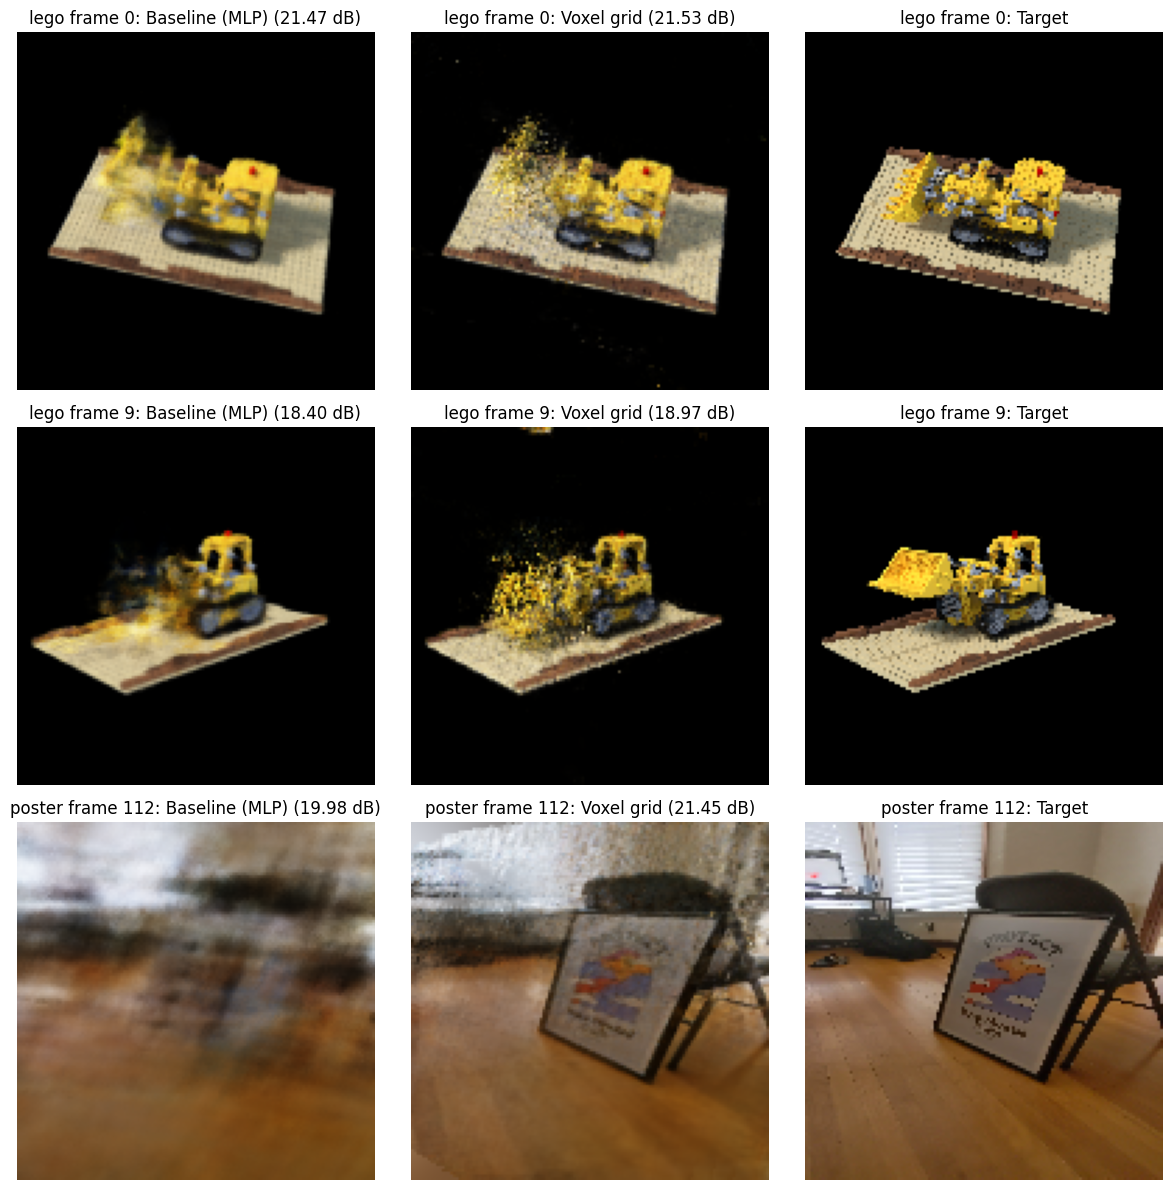

In [ ]:
voxel_models = {"lego": lego_voxel, "poster": poster_voxel}
voxel_rows = [summary_row(name, "Voxel grid", model, evaluate(model, *TEST[name])) for name, model in voxel_models.items()]
comparison = pd.DataFrame(baseline_rows + voxel_rows).sort_values(["Dataset", "Model"])
comparison.to_csv(os.path.join(VOXEL_DIR, f"comparison_{N_ITER}.csv"), index=False)
print(comparison.to_string(index=False))

fig, axes = plt.subplots(len(views), 3, figsize=(12, 4 * len(views)))
for row, (name, fidx) in enumerate(views):
    imgs, cams, _, rgrid = TEST[name]
    target = imgs[fidx]
    for col, (title, img) in enumerate([("Baseline (MLP)", render_view(baseline_models[name], cams, fidx, rgrid)),
                                        ("Voxel grid", render_view(voxel_models[name], cams, fidx, rgrid)),
                                        ("Target", target)]):
        label = title if col == 2 else f"{title} ({calculate_metrics(img, target)[1]:.2f} dB)"
        axes[row, col].imshow(img.cpu())
        axes[row, col].set_title(f"{name} frame {fidx}: {label}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(VOXEL_DIR, f"baseline_vs_voxel_{N_ITER}.png"), dpi=200, bbox_inches="tight")
plt.show()

Dataset          Model  Iteration  Time_min   PSNR_dB     SSIM
   lego Baseline (MLP)       1000  3.511329 20.439542 0.800883
   lego Baseline (MLP)       2000  7.022658 20.846609 0.823799
   lego Baseline (MLP)       3000 10.533986 20.963704 0.833260
   lego Baseline (MLP)       5000 17.556644 20.857639 0.837344
   lego Baseline (MLP)       7000 24.579301 21.142639 0.850357
   lego Baseline (MLP)      10000 35.113288 21.211098 0.855536
   lego Baseline (MLP)      12000 42.135945 21.204486 0.855709
   lego Baseline (MLP)      15000 52.669932 21.221960 0.857254
   lego     Voxel grid       1000  1.348557 21.683868 0.820934
   lego     Voxel grid       2000  2.697115 21.510415 0.828854
   lego     Voxel grid       3000  4.045672 21.299842 0.825618
   lego     Voxel grid       5000  6.742787 21.098369 0.825132
   lego     Voxel grid       7000  9.439901 21.015684 0.827438
   lego     Voxel grid      10000 13.485573 20.913967 0.826568
   lego     Voxel grid      12000 16.182688 20.867936 0

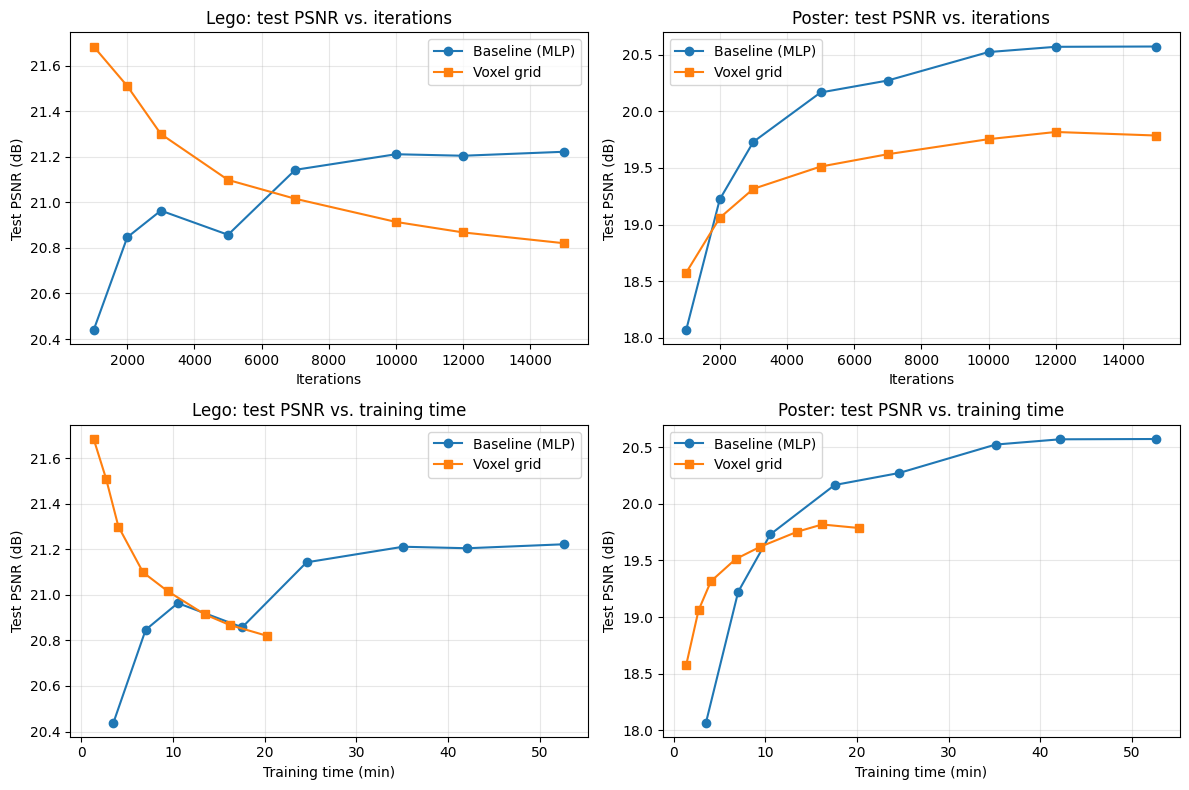

In [ ]:
ITERS = [1000, 2000, 3000, 5000, 7000, 10000, 12000, 15000]
MODELS = [("Baseline (MLP)", "baseline", ms_mlp), ("Voxel grid", "voxel", ms_vox)]

curve_rows = []
for name in ["lego", "poster"]:
    for model_name, kind, ms in MODELS:
        for it in ITERS:
            model = load(kind, name, it)
            res = evaluate(model, *TEST[name])
            curve_rows.append({"Dataset": name, "Model": model_name, "Iteration": it, "Time_min": it * ms / 60000,
                               "PSNR_dB": res.psnr.mean(), "SSIM": res.ssim.mean()})
            del model
            torch.cuda.empty_cache()
curves = pd.DataFrame(curve_rows)
curves.to_csv(os.path.join(PROJECT_DIR, "learning_curves_15k.csv"), index=False)
print(curves.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, name in enumerate(["lego", "poster"]):
    for model_name, marker in [("Baseline (MLP)", "o"), ("Voxel grid", "s")]:
        d = curves[(curves.Dataset == name) & (curves.Model == model_name)]
        axes[0, col].plot(d.Iteration, d.PSNR_dB, marker=marker, label=model_name)
        axes[1, col].plot(d.Time_min, d.PSNR_dB, marker=marker, label=model_name)
    axes[0, col].set(title=f"{name.capitalize()}: test PSNR vs. iterations", xlabel="Iterations", ylabel="Test PSNR (dB)")
    axes[1, col].set(title=f"{name.capitalize()}: test PSNR vs. training time", xlabel="Training time (min)", ylabel="Test PSNR (dB)")
    for r in range(2):
        axes[r, col].grid(alpha=0.3)
        axes[r, col].legend()
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "learning_curves_15k.png"), dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
held_out = poster_test_idx.tolist()
poster_val_frames = held_out[0::2]
poster_test_frames = held_out[1::2]

rows = []
for model_name, kind, ms in MODELS:
    for it in ITERS:
        model = load(kind, "poster", it)
        val = evaluate(model, poster_images, poster_cameras, poster_val_frames, poster_renderer_grid)
        test = evaluate(model, poster_images, poster_cameras, poster_test_frames, poster_renderer_grid)
        rows.append({"Model": model_name, "Iteration": it, "Time_min": it * ms / 60000,
                     "Val_PSNR": val.psnr.mean(), "Test_PSNR": test.psnr.mean(), "Test_SSIM": test.ssim.mean()})
        del model
        torch.cuda.empty_cache()

poster_selection = pd.DataFrame(rows)
poster_selection.to_csv(os.path.join(PROJECT_DIR, "poster_early_stopping.csv"), index=False)
print(poster_selection.to_string(index=False))
print(poster_selection.loc[poster_selection.groupby("Model").Val_PSNR.idxmax()].to_string(index=False))

         Model  Iteration  Time_min  Val_PSNR  Test_PSNR  Test_SSIM
Baseline (MLP)       1000  3.511329 18.038235  18.100617   0.417756
Baseline (MLP)       2000  7.022658 19.223100  19.221871   0.453788
Baseline (MLP)       3000 10.533986 19.775243  19.682659   0.471609
Baseline (MLP)       5000 17.556644 20.221216  20.107829   0.492121
Baseline (MLP)       7000 24.579301 20.313823  20.227725   0.500493
Baseline (MLP)      10000 35.113288 20.576631  20.466672   0.515281
Baseline (MLP)      12000 42.135945 20.640512  20.494410   0.522199
Baseline (MLP)      15000 52.669932 20.642381  20.497843   0.522656
    Voxel grid       1000  1.348557 18.585666  18.563279   0.550830
    Voxel grid       2000  2.697115 19.049803  19.069590   0.571093
    Voxel grid       3000  4.045672 19.308252  19.323528   0.581501
    Voxel grid       5000  6.742787 19.541438  19.480648   0.588702
    Voxel grid       7000  9.439901 19.645364  19.595538   0.595336
    Voxel grid      10000 13.485573 19.792775  1

In [ ]:
val_images, _, val_cameras = load_nerf_data(LEGO_DIR, split="val", device=device, resize_to=IMAGE_SIZE)
val_cameras = fix_camera_convention(val_cameras)
val_images.clamp_(0.0, 1.0)

val_rows = []
for model_name, kind, _ in MODELS:
    for it in ITERS:
        model = load(kind, "lego", it)
        val_psnr = evaluate(model, val_images, val_cameras, range(len(val_images)), lego_renderer_grid).psnr.mean()
        val_rows.append({"Model": model_name, "Iteration": it, "Val_PSNR": val_psnr})
        del model
        torch.cuda.empty_cache()

merged = pd.DataFrame(val_rows).merge(
    curves[curves.Dataset == "lego"][["Model", "Iteration", "Time_min", "PSNR_dB", "SSIM"]], on=["Model", "Iteration"]
).rename(columns={"PSNR_dB": "Test_PSNR", "SSIM": "Test_SSIM"})
merged.to_csv(os.path.join(PROJECT_DIR, "lego_early_stopping.csv"), index=False)
print(merged.to_string(index=False))
print(merged.loc[merged.groupby("Model").Val_PSNR.idxmax()].to_string(index=False))

In [ ]:
GAP_ITERS = [1000, 5000, 15000]
TRAIN_VIEWS = {"lego": (lego_images, lego_cameras, lego_train_idx.tolist()[::5]),
               "poster": (poster_images, poster_cameras, poster_train_idx.tolist()[::5])}

gap_rows = []
for name in ["lego", "poster"]:
    rgrid = TEST[name][3]
    for model_name, kind, _ in MODELS:
        for it in GAP_ITERS:
            model = load(kind, name, it)
            tr = evaluate(model, *TRAIN_VIEWS[name], rgrid).psnr.mean()
            te = evaluate(model, *TEST[name]).psnr.mean()
            gap_rows.append({"Dataset": name, "Model": model_name, "Iteration": it,
                             "Train_PSNR": tr, "Test_PSNR": te, "Gap_dB": tr - te})
            del model
            torch.cuda.empty_cache()
gaps = pd.DataFrame(gap_rows)
gaps.to_csv(os.path.join(PROJECT_DIR, "train_test_gap_15k.csv"), index=False)
print(gaps.to_string(index=False))

In [ ]:
for name in ["lego", "poster"]:
    progress("voxel", "Voxel grid", name)

In [ ]:
LEGO_VIEWS = [0, 9]
imgs, cams, _, rgrid = TEST["lego"]

renders = {}
for _, kind, _ in MODELS:
    for it in SNAPSHOTS:
        model = load(kind, "lego", it)
        for v in LEGO_VIEWS:
            img = render_view(model, cams, v, rgrid)
            renders[(kind, it, v)] = (img.cpu(), calculate_metrics(img, imgs[v])[1])
        del model
        torch.cuda.empty_cache()

for v in LEGO_VIEWS:
    fig, axes = plt.subplots(2, len(SNAPSHOTS) + 1, figsize=(3 * (len(SNAPSHOTS) + 1), 6.4))
    for row, (label, kind, ms) in enumerate(MODELS):
        for col, it in enumerate(SNAPSHOTS):
            img, p = renders[(kind, it, v)]
            axes[row, col].imshow(img)
            axes[row, col].set_title(f"{label}\n{it} it, {it * ms / 60000:.1f} min | {p:.2f} dB", fontsize=9)
            axes[row, col].axis("off")
        axes[row, -1].imshow(imgs[v].cpu())
        axes[row, -1].set_title("Target", fontsize=9)
        axes[row, -1].axis("off")
    fig.suptitle(f"Lego test view {v}: baseline (top) vs. voxel grid (bottom)", fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(PROJECT_DIR, f"lego_baseline_vs_voxel_view{v}.png"), dpi=200, bbox_inches="tight")
    plt.show()